# Week 6: Tool Calling with Validation and Repair, Direct and over MCP

<a href="https://colab.research.google.com/github/jorshimayor/AI-Engineering-Flow_Research/blob/main/jupyter/week6_tool_calling_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Question:** a small model calls two tools to solve shopping problems. When it writes a malformed reply, does telling it what was wrong and asking again help? And does moving the same tools behind an MCP server change anything?

**Readings:** [Toolformer](https://arxiv.org/abs/2302.04761) (Schick et al., 2023): calling a tool is a decision the model makes in text, so the call can be badly formed. [Model Context Protocol specification](https://modelcontextprotocol.io/specification/latest): a standard way to expose tools; a failed call is reported inside the result so the model can see it and retry.

```
 question ──► Qwen2.5 ──► reply ──► parse_reply ──┬─ tool calls ──► lookup_price / calculate ──► results ──┐
                ▲                                  ├─ {"answer": N} ──► score (to the penny)                │
                │                                  └─ malformed ──► repair message (up to 3) ──┐            │
                └───────────────────────────────────────────────────────────────────────────┴────────────┘
 tools reached two ways:  direct  = Python functions, hand-written schemas
                          mcp     = the same functions behind an MCP server (stdio), generated schemas
```

| | |
|---|---|
| Plan and hypotheses | Fixed before the run: [`notes/week_6/README.md`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/notes/week_6/README.md) |
| Code | [`src/tools.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/tools.py) (tools, schemas, parser) · [`src/tool_agent.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/tool_agent.py) (loop, repair, MCP client) · [`src/mcp_server.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/mcp_server.py) · [`src/tool_tasks.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/tool_tasks.py) · [`src/run_tool_bench.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/run_tool_bench.py) |
| Models | Qwen2.5-1.5B-Instruct and Qwen2.5-3B-Instruct, greedy, up to 8 turns and 3 repairs per problem |

**How to read this notebook.** The copy in the repo shows outputs computed from the saved results in `results/week6/`, so every table, figure and transcript is visible without running anything. The tool and MCP cells run for real (they need no model). On Colab with a T4 (`Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`) it re-runs both models over both routes, about 1 hour. Results save to Google Drive after every batch, so a re-run after a disconnect continues where it stopped.

## 0. Setup

On Colab this clones the latest code, installs the pinned packages and keeps results on Google Drive. Run locally, it reads the saved results in the repo.

In [1]:
import os, sys
from pathlib import Path
ON_COLAB = "google.colab" in sys.modules
try:
    import torch
    GPU = torch.cuda.is_available()
except ImportError:
    GPU = False
print("Colab:", ON_COLAB, "| GPU:", torch.cuda.get_device_name(0) if GPU else "none (using the saved results)")

Colab: False | GPU: none (using the saved results)


In [2]:
REPO = "https://github.com/jorshimayor/AI-Engineering-Flow_Research.git"
BRANCH = "main"
RESULTS = "results/week6"
if ON_COLAB:
    BASE = "/content"
    CODE = os.path.join(BASE, "AI-Engineering-Flow_Research")
    if not os.path.exists(CODE):
        !git clone --depth 1 --branch {BRANCH} {REPO} {CODE}
    %cd {CODE}
    !git fetch -q --depth 1 origin {BRANCH} && git checkout -q -B {BRANCH} FETCH_HEAD
    !pip install -q "transformers==4.49.0" accelerate "mcp==2.3.0" jsonschema
    !git log --oneline -1
else:
    if Path.cwd().name == "jupyter":
        os.chdir("..")
    BASE = os.getcwd()
print("working in the repo:", Path.cwd().name)

working in the repo: AI-Engineering


In [3]:
USE_DRIVE = ON_COLAB
if USE_DRIVE:
    import shutil
    from google.colab import drive
    drive.mount("/content/drive")
    target = "/content/drive/MyDrive/AI-Engineering/week6"
    os.makedirs(target, exist_ok=True)
    if os.path.isdir(RESULTS) and not os.path.islink(RESULTS):   # keep files the repo already has here
        for f in os.listdir(RESULTS):
            if os.path.isfile(os.path.join(RESULTS, f)) and not os.path.exists(os.path.join(target, f)):
                shutil.copy(os.path.join(RESULTS, f), target)
        shutil.rmtree(RESULTS)
    os.makedirs(os.path.dirname(RESULTS), exist_ok=True)
    if not os.path.islink(RESULTS):
        os.symlink(target, RESULTS)
os.makedirs(RESULTS, exist_ok=True)
print("results in:", os.path.realpath(RESULTS) if ON_COLAB else RESULTS)

results in: results/week6


In [4]:
import importlib, inspect, json, textwrap
sys.path.insert(0, "src")
import numpy as np, pandas as pd
from IPython.display import Code, Image, Markdown, display
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

def show(obj):
    """Display the source of a function or class from src/, so the notebook shows the code that actually runs."""
    display(Code(inspect.getsource(obj), language="python"))

def clip(text, n=600):
    text = str(text)
    return text if len(text) <= n else text[:n] + f" … [{len(text) - n} more characters]"

import tools, tool_tasks, tool_agent, run_tool_bench
for m in (tool_tasks, tools, tool_agent, run_tool_bench): importlib.reload(m)
assert (tools.TOOLS_VERSION, tool_tasks.TASKS_VERSION) == ("1.0", "1.0"), "stale code: Runtime → Disconnect and delete runtime, then Run all"

## 1. The tasks

Shopping questions in 6 shapes. Prices are random (fixed seed), so the model cannot know them and has to call `lookup_price`. Gold answers are exact to the penny. Test problems use 24 catalogue items that no development work ever saw; dev problems use the other 8.

In [5]:
PROBLEMS = tool_tasks.make_problems("test", 200)
print(len(PROBLEMS), "test problems")
pd.DataFrame(PROBLEMS)[["pid", "template", "question", "gold"]].groupby("template").head(1)

200 test problems


,pid,template,question,gold
0,0,two_items,Ada buys 6 jars of basil pesto and 2 loaves of sourdough loaf. How much does she pay in pounds?,56.92
1,1,three_items,"Ben buys 9 bags of ground coffee, 7 balls of mozzarella and 7 jars of basil pesto. What is the total cost in pounds?",208.39
2,2,change,"Chloe buys 5 punnets of cherry tomatoes and 8 packs of smoked salmon, and pays with a 100 pound note. How much change does she get in po...",37.90
3,3,discount,Dev buys 6 bags of frozen peas and 3 jars of basil pesto. The shop takes 20% off the total. How much does he pay in pounds?,39.17
4,4,budget,Ella has 30 pounds to spend on sourdough loaf only. How many whole loaves of sourdough loaf can she buy?,2.00
5,5,difference,How many pounds more do 3 bags of lemons cost than 2 bottles of maple syrup? Give a negative number if they cost less.,17.38


In [6]:
pd.DataFrame([{"item": k, "price (£)": float(v["price"]), "unit": v["unit"], "split": "dev" if k in tool_tasks.DEV_ITEMS else "test"}
              for k, v in tool_tasks.CATALOGUE.items()]).head(12)

,item,price (£),unit,split
0,basmati rice,2.88,kg,dev
1,olive oil,6.99,litre,dev
2,plain flour,10.74,kg,dev
3,brown eggs,10.93,dozen,dev
4,cheddar cheese,2.55,block,dev
5,oat milk,5.02,carton,dev
6,green tea,12.75,box,dev
7,dark chocolate,11.84,bar,dev
8,cherry tomatoes,9.06,punnet,test
9,red onions,12.17,kg,test


## 2. The two tools

`lookup_price` reads the catalogue and suggests a close match for an unknown item. `calculate` reuses Week 3's safe parser (never `eval`). A failure raises `ToolError`, and the route turns it into a result the model can read.

In [7]:
show(tools.lookup_price); show(tools.calculate); show(tools.DirectTools)

def lookup_price(item: str) -> dict:
    key = item.strip().lower()
    if key not in CATALOGUE:
        close = difflib.get_close_matches(key, CATALOGUE, n=1, cutoff=0.75)
        raise ToolError(f"Unknown item {item!r}." + (f" Did you mean {close[0]!r}?" if close else ""))
    return {"item": key, "price": float(CATALOGUE[key]["price"]), "unit": CATALOGUE[key]["unit"], "currency": "GBP"}

def calculate(expression: str) -> dict:
    out = _safe_calc(expression)
    if out.startswith("Error"):
        raise ToolError(out.removeprefix("Error: "))
    return {"result": float(out)}

class DirectTools:
    """Tools called as plain Python functions."""
    route = "direct"

    def __init__(self):
        self.schemas = SCHEMAS

    def call(self, name: str, arguments: dict) -> tuple[str, bool]:
        """Returns (content for the model, is_error)."""
        try:
            return json.dumps(FUNCTIONS[name](**arguments)), False
        except ToolError as e:
            return json.dumps({"error": str(e)}), True

    def close(self):
        pass

In [8]:
direct = tools.DirectTools()
for name, args in [("lookup_price", {"item": "olive oil"}), ("lookup_price", {"item": "olive oils"}),
                   ("lookup_price", {"item": "bottle of maple syrup"}), ("calculate", {"expression": "3 * 2.5 + 4"}),
                   ("calculate", {"expression": "6 * lookup_price('basil pesto')"}), ("calculate", {"expression": "__import__('os')"})]:
    content, err = direct.call(name, args)
    print(f"{'ERROR' if err else 'ok   '} {name}({args}) → {content}")

ok    lookup_price({'item': 'olive oil'}) → {"item": "olive oil", "price": 6.99, "unit": "litre", "currency": "GBP"}
ERROR lookup_price({'item': 'olive oils'}) → {"error": "Unknown item 'olive oils'. Did you mean 'olive oil'?"}
ERROR lookup_price({'item': 'bottle of maple syrup'}) → {"error": "Unknown item 'bottle of maple syrup'."}
ok    calculate({'expression': '3 * 2.5 + 4'}) → {"result": 11.5}
ERROR calculate({'expression': "6 * lookup_price('basil pesto')"}) → {"error": "could not evaluate \"6 * lookup_price('basil pesto')\" (ValueError). Use only numbers and + - * / ( )."}
ERROR calculate({'expression': "__import__('os')"}) → {"error": "could not evaluate \"__import__('os')\" (ValueError). Use only numbers and + - * / ( )."}


Note the unit-prefixed name ("bottle of maple syrup") gets no "Did you mean" hint: the match is not close enough. That matters later.

## 3. Schemas: written by hand vs generated by MCP

The direct route's schemas are written as JSON by hand. The MCP route starts [`src/mcp_server.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/mcp_server.py) as a subprocess and uses whatever schemas the server advertises, generated from type hints and docstrings. This cell starts the real server (no model needed).

In [9]:
show(tool_agent.MCPTools.__init__)

def __init__(self, server_script: Path = Path(__file__).parent / "mcp_server.py", errlog=None):
        from mcp import ClientSession, StdioServerParameters
        from mcp.client.stdio import stdio_client

        self.loop = asyncio.new_event_loop()
        threading.Thread(target=self.loop.run_forever, daemon=True).start()
        ready = concurrent.futures.Future()
        errlog = errlog or open(os.devnull, "w")   # the server logs every tool failure to stderr

        async def lifecycle():
            # anyio needs the connection opened and closed by the same task, so one task holds it
            self._closed = asyncio.Event()
            try:
                async with stdio_client(StdioServerParameters(command=sys.executable, args=[str(server_script)]),
                                        errlog=errlog) as (read, write):
                    async with ClientSession(read, write) as session:
                        self.session = session
                        await session.initialize()
                        listed = await session.list_tools()
                        ready.set_result([{"type": "function", "function": {
                            "name": t.name, "description": t.description, "parameters": t.input_schema}}
                            for t in listed.tools])
                        await self._closed.wait()
            except Exception as e:
                if not ready.done():
                    ready.set_exception(e)
                raise

        self._task = asyncio.run_coroutine_threadsafe(lifecycle(), self.loop)
        self.schemas = ready.result(timeout=60)

In [10]:
mcp = tool_agent.MCPTools()
for hand, gen in zip(tools.SCHEMAS, mcp.schemas):
    print(f"══ {hand['function']['name']} ══")
    print("hand-written:", json.dumps(hand["function"]["parameters"]))
    print("MCP:         ", json.dumps(gen["function"]["parameters"]))
    print()

══ lookup_price ══
hand-written: {"type": "object", "additionalProperties": false, "required": ["item"], "properties": {"item": {"type": "string", "description": "Catalogue item name, e.g. \"olive oil\""}}}
MCP:          {"properties": {"item": {"description": "Catalogue item name, e.g. \"olive oil\"", "title": "Item", "type": "string"}}, "required": ["item"], "type": "object", "title": "lookup_priceArguments"}

══ calculate ══
hand-written: {"type": "object", "additionalProperties": false, "required": ["expression"], "properties": {"expression": {"type": "string", "description": "Numbers and + - * / // ( ) only, e.g. \"3 * 2.5 + 4\""}}}
MCP:          {"properties": {"expression": {"description": "Numbers and + - * / // ( ) only, e.g. \"3 * 2.5 + 4\"", "title": "Expression", "type": "string"}}, "required": ["expression"], "type": "object", "title": "calculateArguments"}



The MCP schema leaves out `additionalProperties: false` (so extra arguments pass) and adds `title` fields. Errors also come back differently:

In [11]:
for name, args in [("lookup_price", {"item": "olive oil"}), ("lookup_price", {"item": "olive oils"}), ("calculate", {"expression": "1/0"})]:
    print(f"{name}({args})")
    print("   direct:", direct.call(name, args)[0])
    print("   MCP:   ", mcp.call(name, args)[0].replace("\n", " "))
mcp.close()

lookup_price({'item': 'olive oil'})
   direct: {"item": "olive oil", "price": 6.99, "unit": "litre", "currency": "GBP"}
   MCP:    {   "item": "olive oil",   "price": 6.99,   "unit": "litre",   "currency": "GBP" }
lookup_price({'item': 'olive oils'})
   direct: {"error": "Unknown item 'olive oils'. Did you mean 'olive oil'?"}
   MCP:    {"error": "Error executing tool lookup_price: Unknown item 'olive oils'. Did you mean 'olive oil'?"}
calculate({'expression': '1/0'})
   direct: {"error": "division by zero"}
   MCP:    {"error": "Error executing tool calculate: division by zero"}


| | Direct | MCP |
|---|---|---|
| Result text | Compact JSON | Pretty-printed JSON |
| Tool errors | The reason, as JSON | Prefixed with "Error executing tool <name>:" |
| Cost per call | about 0.01 ms | about 2 ms (stdio round trip), plus about 3 s to start the server |

Integration code, counted from the source files (non-blank, non-comment lines):

In [12]:
here = Path("src")
print("direct route:", run_tool_bench.loc_section(here / "tools.py", "# -- direct route", "# -- parsing"), "lines (hand-written schemas + DirectTools)")
print("MCP route:   ", run_tool_bench.loc(here / "mcp_server.py"), "lines of server +", run_tool_bench.loc(tool_agent.MCPTools), "lines of client")

direct route: 26 lines (hand-written schemas + DirectTools)
MCP route:    33 lines of server + 38 lines of client


## 4. Validating every reply

The system prompt, then the parser. Every reply is sorted into tool calls, a final answer, or one of four malformed types: invalid JSON, unknown tool, arguments that fail the schema, a final answer that is not `{"answer": <number>}`.

In [13]:
print(tool_agent.SYSTEM)

You are a shopping assistant. You do not know any prices: call lookup_price for every item, and use calculate for every arithmetic step. Money is in pounds, rounded to 2 decimal places. When you have the result, reply with only the JSON object {"answer": <number>} and nothing else.


In [14]:
show(tools.parse_reply)

def parse_reply(text: str, schemas: list[dict]) -> dict:
    """Classify a reply. Returns {"kind": "calls"|"final"|"malformed", ...}.
    calls: [{"name", "arguments"}]; final: "answer"; malformed: "type", "detail"."""
    params = {s["function"]["name"]: s["function"]["parameters"] for s in schemas}
    blocks = _CALL.findall(text)
    if "<tool_call>" in text and len(blocks) < text.count("<tool_call>"):
        return dict(kind="malformed", type="json_error", detail="a <tool_call> tag was opened but not closed")
    if blocks:
        calls = []
        for raw in blocks:
            try:
                obj = json.loads(raw)
            except json.JSONDecodeError as e:
                return dict(kind="malformed", type="json_error", detail=f"tool call is not valid JSON ({e.msg})")
            if not isinstance(obj, dict) or not isinstance(obj.get("name"), str):
                return dict(kind="malformed", type="json_error", detail='tool call must be {"name": ..., "arguments": {...}}')
            if obj["name"] not in params:
                return dict(kind="malformed", type="unknown_tool",
                            detail=f"no tool named {obj['name']!r}; tools are {', '.join(params)}")
            args = obj.get("arguments")
            if not isinstance(args, dict):
                return dict(kind="malformed", type="schema_error", detail=f"arguments for {obj['name']} must be a JSON object")
            err = _first_error(args, params[obj["name"]])
            if err:
                return dict(kind="malformed", type="schema_error", detail=f"{obj['name']} arguments: {err}")
            calls.append(dict(name=obj["name"], arguments=args))
        return dict(kind="calls", calls=calls)
    body = text.strip()
    m = _FENCE.match(body)
    body = m.group(1) if m else body
    try:
        obj = json.loads(body)
    except json.JSONDecodeError:
        return dict(kind="malformed", type="final_format_error",
                    detail='no tool call, and the reply is not the JSON object {"answer": <number>}')
    err = _first_error(obj, FINAL_SCHEMA)
    if err:
        return dict(kind="malformed", type="final_format_error", detail=f"final answer: {err}")
    return dict(kind="final", answer=float(obj["answer"]))

In [15]:
sys.path.insert(0, "tests")
from test_week6 import PARSER_CASES
rows = []
for reply, kind, mtype in PARSER_CASES:
    r = tools.parse_reply(reply, tools.SCHEMAS)
    rows.append({"reply": reply.replace("\n", " "), "kind": r["kind"], "type": r.get("type", ""), "detail": r.get("detail", ""),
                 "as expected": (r["kind"], r.get("type")) == (kind, mtype)})
pd.DataFrame(rows)

,reply,kind,type,detail,as expected
0,"<tool_call> {""name"": ""lookup_price"", ""arguments"": {""item"": ""olive oil""}} </tool_call>",calls,,,True
1,"<tool_call> {""name"": ""lookup_price"", ""arguments"": {""item"": ""a""}} </tool_call><tool_call> {""name"": ""calculate"", ""arguments"": {""expression...",calls,,,True
2,"{""answer"": 12.5}",final,,,True
3,"```json {""answer"": 3} ```",final,,,True
4,"<tool_call> {""name"": ""calculate"", ""arguments"": {""expression"": ""1+1""}}",malformed,json_error,a <tool_call> tag was opened but not closed,True
5,"<tool_call> {""name"": ""calculate"", ""arguments"": {""expression"": 1+1}} </tool_call>",malformed,json_error,"tool call is not valid JSON (Expecting ',' delimiter)",True
6,"<tool_call>[""calculate""]</tool_call>",malformed,json_error,"tool call must be {""name"": ..., ""arguments"": {...}}",True
7,"<tool_call> {""name"": ""add"", ""arguments"": {""a"": 1, ""b"": 2}} </tool_call>",malformed,unknown_tool,"no tool named 'add'; tools are lookup_price, calculate",True
8,"<tool_call> {""name"": ""calculate"", ""arguments"": {}} </tool_call>",malformed,schema_error,calculate arguments: 'expression' is a required property,True
9,"<tool_call> {""name"": ""calculate"", ""arguments"": {""expression"": 5}} </tool_call>",malformed,schema_error,calculate arguments: expression: 5 is not of type 'string',True


A malformed reply is never executed. The model gets this message and tries again, up to 3 times:

In [16]:
print(tools.repair_message(tools.parse_reply('{"answer": "18.00"}', tools.SCHEMAS)["detail"]))

Your last reply could not be used: final answer: answer: '18.00' is not of type 'number'. Reply again with either tool calls in <tool_call></tool_call> tags, or, if you know the answer, only the JSON object {"answer": <number>}.


## 5. The loop

All unfinished conversations generate their next turn together, which keeps the GPU busy:

In [17]:
show(tool_agent.run_problems)

def run_problems(llm, problems: list[dict], backend, max_turns: int = 8, max_repairs: int = 3,
                 max_new_tokens: int = 256, batch_size: int = 16, on_done=None) -> list[dict]:
    """Run each problem to a final answer, a turn limit or a repair limit. Returns one record per problem."""
    states = [dict(p=p, messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": p["question"]}],
                   events=[], turns=0, repairs=0, tool_calls=0, tool_errors=0, tool_seconds=[], tokens_in=0,
                   tokens_out=0, seconds=0.0, pred=None, status=None) for p in problems]
    pending = list(states)
    while pending:
        batch, pending = pending[:batch_size], pending[batch_size:]
        active = batch
        while active:
            t0 = time.time()
            gens = llm.generate([s["messages"] for s in active], max_new_tokens, tools=backend.schemas)
            dt = (time.time() - t0) / len(active)
            for s, (text, n_in, n_out) in zip(active, gens):
                s["turns"] += 1; s["tokens_in"] += n_in; s["tokens_out"] += n_out; s["seconds"] += dt
                r = parse_reply(text, backend.schemas)
                if r["kind"] == "malformed":
                    s["events"].append(dict(turn=s["turns"], type=r["type"], detail=r["detail"], output=text))
                    if s["repairs"] >= max_repairs:
                        s["status"] = "repairs_exhausted"; continue
                    s["repairs"] += 1
                    s["messages"] += [{"role": "assistant", "content": text},
                                      {"role": "user", "content": repair_message(r["detail"])}]
                elif r["kind"] == "final":
                    s["pred"], s["status"] = r["answer"], "final"
                    s["messages"].append({"role": "assistant", "content": text})
                    continue
                else:
                    s["messages"].append(_assistant_turn(text, r["calls"]))
                    for c in r["calls"]:
                        t1 = time.perf_counter()
                        content, is_error = backend.call(c["name"], c["arguments"])
                        s["tool_seconds"].append(time.perf_counter() - t1)
                        s["tool_calls"] += 1; s["tool_errors"] += is_error
                        s["messages"].append({"role": "tool", "name": c["name"], "content": content})
                if s["turns"] >= max_turns:
                    s["status"] = "max_turns"
            active = [s for s in active if s["status"] is None]
        for s in batch:
            if on_done:
                on_done(record(s, backend.route))
    return [record(s, backend.route) for s in states]

## 6. Run (GPU only)

First the model-free tests and a 12-problem dev check on the 1.5B model, then both models over both routes. Without a GPU this cell only reports what is already saved.

In [18]:
MODELS = ["Qwen/Qwen2.5-1.5B-Instruct", "Qwen/Qwen2.5-3B-Instruct"]
if GPU:
    import gc
    !python tests/test_week6.py
    from run_prompt_bench import BatchLLM
    llm = BatchLLM(MODELS[0])
    _ = run_tool_bench.summary([run_tool_bench.run(MODELS[0], ["direct"], "dev", 12, Path(RESULTS) / "dev" / "Qwen2.5-1.5B-Instruct.jsonl", 12, llm=llm)])
    for model in MODELS:
        if llm is None or llm.name != model:
            llm = None; gc.collect(); torch.cuda.empty_cache()
            llm = BatchLLM(model)
        run_tool_bench.run(model, ["direct", "mcp"], "test", 200, Path(RESULTS) / f"{model.split('/')[-1]}.jsonl", 16, llm=llm)
else:
    for f in sorted(Path(RESULTS).glob("*.jsonl")):
        print(f"saved: {f}  ({sum(1 for _ in f.open())} runs)")

saved: results/week6/Qwen2.5-1.5B-Instruct.jsonl  (400 runs)
saved: results/week6/Qwen2.5-3B-Instruct.jsonl  (400 runs)


## 7. Results

The runner's own summary: per model and route, success with 95% Wilson intervals, the fail-closed score (the same run, scored as failed at its first malformed reply), malformed runs and how many were recovered, then H1, H2 and the exploratory failure breakdown.

In [19]:
PATHS = sorted(Path(RESULTS).glob("Qwen*.jsonl"))
RES = run_tool_bench.summary(PATHS)


=== Qwen/Qwen2.5-1.5B-Instruct  (results/week6/Qwen2.5-1.5B-Instruct.jsonl)
route      n  success          95% CI  fail-closed  runs w/ malformed  recovered  tool calls  tool errs  turns  tool ms
direct   200     1.5%   0.5% to  4.3%         1.5%              10.0%       0.0%        3.04       1.10   2.21     0.03
        malformed replies: {'final_format_error': 39, 'json_error': 3, 'schema_error': 3} | end states: {'final': 192, 'repairs_exhausted': 8}
mcp      200     1.5%   0.5% to  4.3%         1.5%              10.5%       0.0%        3.23       1.34   2.18     2.27
        malformed replies: {'final_format_error': 37, 'json_error': 2} | end states: {'final': 194, 'repairs_exhausted': 6}


  H2 MCP - direct: +0.0 pts (95% CI -2.5 to +2.5), discordant (3, 3), margin ±5 -> equivalent

=== Qwen/Qwen2.5-3B-Instruct  (results/week6/Qwen2.5-3B-Instruct.jsonl)
route      n  success          95% CI  fail-closed  runs w/ malformed  recovered  tool calls  tool errs  turns  tool ms
direct   200    31.5%  25.5% to 38.2%        22.5%              39.0%      23.1%        4.18       1.86   3.67     0.05
        malformed replies: {'final_format_error': 153, 'json_error': 29, 'unknown_tool': 2, 'schema_error': 2} | end states: {'final': 170, 'repairs_exhausted': 28, 'max_turns': 2}
mcp      200    25.5%  20.0% to 32.0%        24.5%              27.0%       3.7%        3.79       1.65   3.31     2.37
        malformed replies: {'final_format_error': 124, 'json_error': 33, 'schema_error': 3, 'unknown_tool': 4} | end states: {'final': 168, 'max_turns': 3, 'repairs_exhausted': 29}


  H2 MCP - direct: -6.0 pts (95% CI -13.0 to +0.5), discordant (17, 29), margin ±5 -> inconclusive
  H1 Qwen/Qwen2.5-1.5B-Instruct: repair - fail-closed +0.0 pts (95% CI +0.0 to +0.0), Holm p = 1
  H1 Qwen/Qwen2.5-3B-Instruct: repair - fail-closed +9.0 pts (95% CI +5.5 to +13.0), Holm p = 1.5e-05

Exploratory: how runs failed (share of the 200 runs unless stated)
model                  route   calc in 1st reply  lookup err  no good calc  success | calc ok  success | no calc ok  same bad reply
Qwen2.5-1.5B-Instruct  direct              95.5%       28.5%         52.0%     3.4% of  88        0.0% of 112            4.0%
                               malformed shapes: {'answer as a string': 38, 'schema_error': 3, 'json_error': 2, 'final_format_error': 1, 'lookup_price nested inside calculate': 1}
Qwen2.5-1.5B-Instruct  mcp                 96.5%       30.5%         64.0%     0.0% of  66        2.2% of 134            3.0%
                               malformed shapes: {'answer as a string'

Qwen2.5-3B-Instruct    direct              71.0%       25.0%         28.5%    51.7% of 120        1.2% of  80            8.0%
                               malformed shapes: {"stray '>' before the JSON": 79, 'answer as a string': 45, 'tool call without <tool_call> tags': 27, 'lookup_price nested inside calculate': 20, 'json_error': 8, 'final_format_error': 3, 'unknown_tool': 2, 'schema_error': 2}
Qwen2.5-3B-Instruct    mcp                 70.5%       29.0%         27.5%    43.6% of 117        0.0% of  83           10.0%
                               malformed shapes: {"stray '>' before the JSON": 103, 'lookup_price nested inside calculate': 24, 'tool call without <tool_call> tags': 11, 'json_error': 9, 'answer as a string': 8, 'unknown_tool': 4, 'schema_error': 3, 'final_format_error': 2}

Integration code (non-blank, non-comment lines): direct route = 26 (hand-written schemas + DirectTools); MCP route = server 33 + client 38


The same numbers as a table:

In [20]:
from stats import wilson_ci
RUNS = [json.loads(l) for f in PATHS for l in f.open()]
df = pd.DataFrame(RUNS)
df["size"] = df.model.str.extract(r"(\d\.?\d?B)")[0]

def row(g):
    k, n = int(g.correct.sum()), len(g); lo, hi = wilson_ci(k, n)
    bad = g[g.malformed.map(len) > 0]
    return pd.Series({"success": k / n, "95% CI": f"{lo:.1%} to {hi:.1%}", "fail-closed": g.correct_fail_closed.mean(),
                      "runs with a malformed reply": len(bad) / n, "recovered": f"{int(bad.correct.sum())} of {len(bad)}",
                      "tool calls": g.tool_calls.mean(), "tool errors": g.tool_errors.mean(), "turns": g.turns.mean(),
                      "median ms per call": np.median([t for ts in g.tool_seconds for t in ts]) * 1000})

T = df.groupby(["size", "route"]).apply(row, include_groups=False).reset_index()
(T.style.format({"success": "{:.1%}", "fail-closed": "{:.1%}", "runs with a malformed reply": "{:.1%}", "tool calls": "{:.2f}",
                 "tool errors": "{:.2f}", "turns": "{:.2f}", "median ms per call": "{:.2f}"})
  .bar(subset=["success"], color="#9ec5f0", vmin=0, vmax=1).hide(axis="index"))

size,route,success,95% CI,fail-closed,runs with a malformed reply,recovered,tool calls,tool errors,turns,median ms per call
1.5B,direct,1.5%,0.5% to 4.3%,1.5%,10.0%,0 of 20,3.04,1.10,2.21,0.03
1.5B,mcp,1.5%,0.5% to 4.3%,1.5%,10.5%,0 of 21,3.23,1.34,2.18,2.27
3B,direct,31.5%,25.5% to 38.2%,22.5%,39.0%,18 of 78,4.18,1.86,3.67,0.05
3B,mcp,25.5%,20.0% to 32.0%,24.5%,27.0%,2 of 54,3.79,1.65,3.31,2.37


### Confirmatory hypotheses

- **H1:** validation with repair solves at least 5 points more problems than failing closed, at each size (direct route; Holm p < 0.05, CI lower bound > 0, effect ≥ 5).
- **H2:** MCP within ±5 points of direct, at each size (whole paired CI inside ±5).

In [21]:
H = []
for model, r in RES.items():
    size = model.split("-")[1]
    if "h1" in r:
        h = r["h1"]
        H.append(dict(hypothesis="H1: repair − fail-closed", size=size, effect=f"{h['effect']*100:+.1f}", CI=f"{h['lo']*100:+.1f} to {h['hi']*100:+.1f}",
                      p=f"{h['p_holm']:.2g} (Holm)", verdict="supported" if h["p_holm"] < 0.05 and h["lo"] > 0 and h["effect"] >= 0.05 else "not supported"))
    if "h2" in r:
        h = r["h2"]
        H.append(dict(hypothesis="H2: MCP − direct", size=size, effect=f"{h['effect']*100:+.1f}", CI=f"{h['lo']*100:+.1f} to {h['hi']*100:+.1f}",
                      p="", verdict=h["verdict"]))
pd.DataFrame(H).sort_values(["hypothesis", "size"])

,hypothesis,size,effect,CI,p,verdict
0,H1: repair − fail-closed,1.5B,+0.0,+0.0 to +0.0,1 (Holm),not supported
2,H1: repair − fail-closed,3B,+9.0,+5.5 to +13.0,1.5e-05 (Holm),supported
1,H2: MCP − direct,1.5B,+0.0,-2.5 to +2.5,,equivalent
3,H2: MCP − direct,3B,-6.0,-13.0 to +0.5,,inconclusive


**H1 holds at 3B and fails at 1.5B.** Repair turned 18 failed 3B runs into correct answers and broke none. At 1.5B there was nothing to recover: the model solves 3 problems on either route, a floor the 12-problem dev check should have caught.

**H2 is inconclusive at 3B.** MCP trails direct by 6 points, CI −13.0 to +0.5. Before repair the routes are level; the gap opens in the repair loop (direct recovered 18 of 78 malformed runs, MCP 2 of 54). At 1.5B "equivalent" says little, as both routes sit at the floor.

### Figures

**week6_success_by_route**

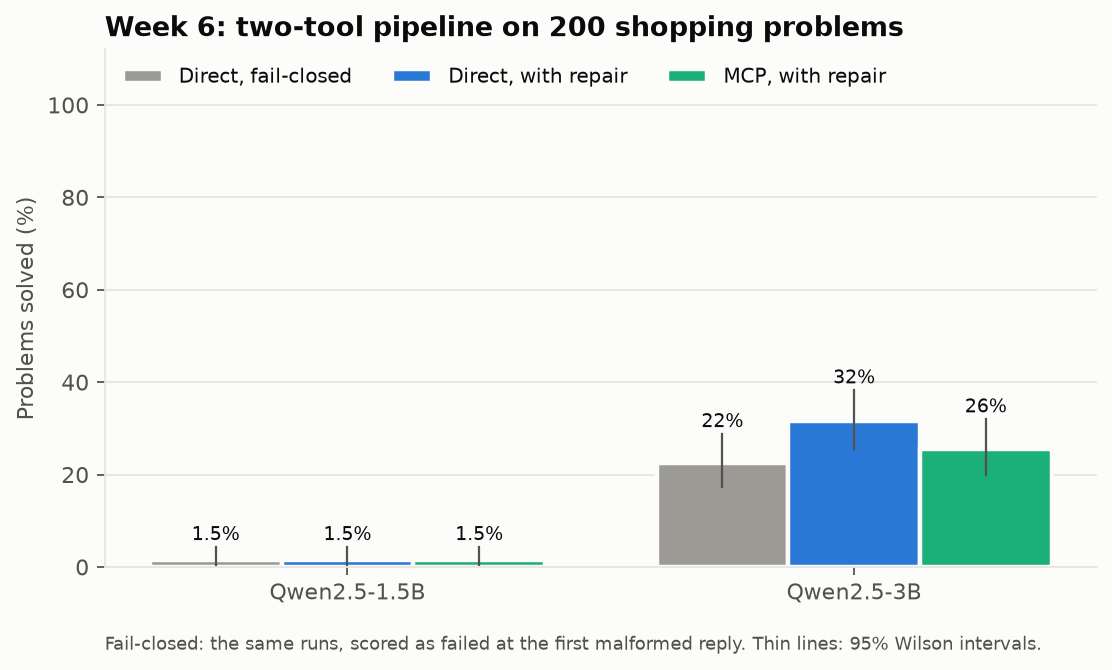

**week6_malformed_types**

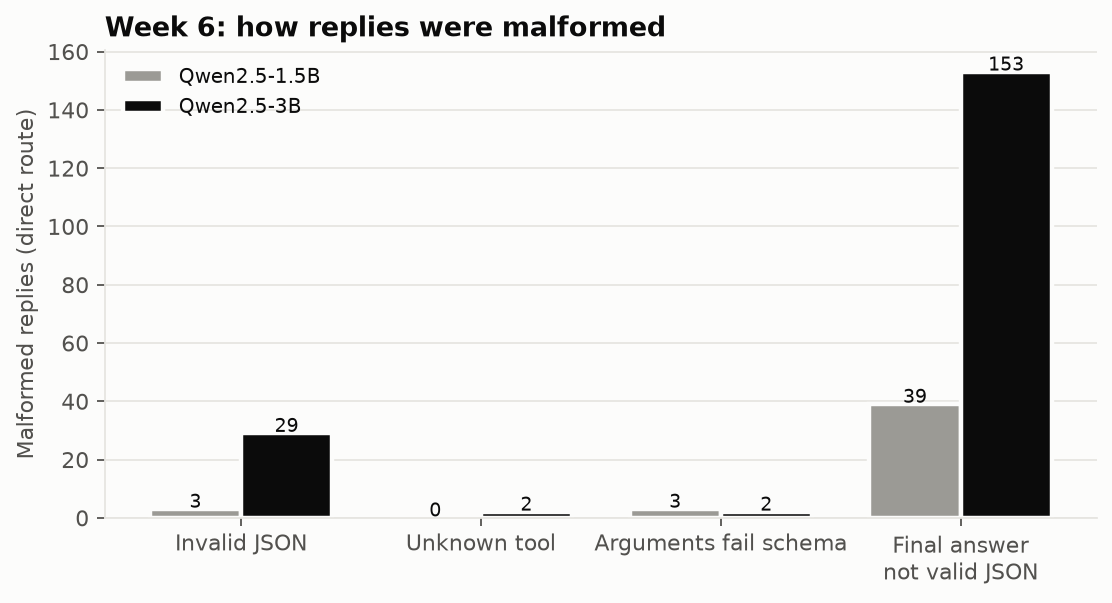

In [22]:
import figures
importlib.reload(figures)
NAMES = ['week6_success_by_route', 'week6_malformed_types']
if GPU:   # fresh results: redraw the figures next to them
    figures.OUT = Path(RESULTS) / "figures"
    figures.RES = Path("results")
    figures.week6_success_by_route()
    figures.week6_malformed_types()
    folder = figures.OUT
else:     # saved results: show the committed figures
    folder = Path("results/figures")
for name in NAMES:
    display(Markdown(f"**{name}**"))
    display(Image(str(folder / f"{name}.png")))

## 8. How the runs went wrong

`failures()` breaks every run down further: how often `calculate` was sent in the first reply, before any price came back; unknown items; answers given with no successful calculation; and success with and without a working calculation.

In [23]:
F = run_tool_bench.failures(PATHS)
pd.DataFrame([{"model": m, "route": route, **{k: v for k, v in row.items() if k != "malformed_shapes"}}
              for m, routes in F.items() for route, row in routes.items()]).style.format(
    {"calc_in_first_reply": "{:.1%}", "lookup_error": "{:.1%}", "final_without_calc": "{:.1%}", "success_calc_ok": "{:.1%}",
     "success_no_calc_ok": "{:.1%}", "same_bad_reply": "{:.1%}"}).hide(axis="index")


Exploratory: how runs failed (share of the 200 runs unless stated)
model                  route   calc in 1st reply  lookup err  no good calc  success | calc ok  success | no calc ok  same bad reply
Qwen2.5-1.5B-Instruct  direct              95.5%       28.5%         52.0%     3.4% of  88        0.0% of 112            4.0%
                               malformed shapes: {'answer as a string': 38, 'schema_error': 3, 'json_error': 2, 'final_format_error': 1, 'lookup_price nested inside calculate': 1}
Qwen2.5-1.5B-Instruct  mcp                 96.5%       30.5%         64.0%     0.0% of  66        2.2% of 134            3.0%
                               malformed shapes: {'answer as a string': 31, 'final_format_error': 6, 'lookup_price nested inside calculate': 1, 'json_error': 1}
Qwen2.5-3B-Instruct    direct              71.0%       25.0%         28.5%    51.7% of 120        1.2% of  80            8.0%
                               malformed shapes: {"stray '>' before the JSON": 79

model,route,calc_in_first_reply,lookup_error,final_without_calc,n_calc_ok,success_calc_ok,n_no_calc_ok,success_no_calc_ok,same_bad_reply
Qwen2.5-1.5B-Instruct,direct,95.5%,28.5%,52.0%,88,3.4%,112,0.0%,4.0%
Qwen2.5-1.5B-Instruct,mcp,96.5%,30.5%,64.0%,66,0.0%,134,2.2%,3.0%
Qwen2.5-3B-Instruct,direct,71.0%,25.0%,28.5%,120,51.7%,80,1.2%,8.0%
Qwen2.5-3B-Instruct,mcp,70.5%,29.0%,27.5%,117,43.6%,83,0.0%,10.0%


Malformed replies sorted into finer shapes, from their text:

In [24]:
pd.DataFrame({f"{m} {route}": row["malformed_shapes"] for m, routes in F.items() for route, row in routes.items()}).fillna(0).astype(int)

,Qwen2.5-1.5B-Instruct direct,Qwen2.5-1.5B-Instruct mcp,Qwen2.5-3B-Instruct direct,Qwen2.5-3B-Instruct mcp
answer as a string,38,31,45,8
json_error,2,1,8,9
schema_error,3,0,2,3
final_format_error,1,6,3,2
lookup_price nested inside calculate,1,1,20,24
tool call without <tool_call> tags,0,0,27,11
stray '>' before the JSON,0,0,79,103
unknown_tool,0,0,2,4


### Transcripts

A helper that prints one run as the model saw it:

In [25]:
def transcript(r, width=220):
    print(f"[{r['model'].split('/')[-1]} · {r['route']} · problem {r['pid']} · {r['template']}]  gold {r['gold']}  answer {r['pred']}  "
          f"status {r['status']}  {'CORRECT' if r['correct'] else 'wrong'}")
    for m in r["messages"][1:]:
        if m.get("tool_calls"):
            calls = ", ".join(f"{c['function']['name']}({json.dumps(c['function']['arguments'])})" for c in m["tool_calls"])
            print(f"  assistant → {clip(calls, width)}")
        else:
            print(f"  {m['role']:9}{'(' + m['name'] + ')' if m.get('name') else ''}: {clip(m['content'], width)}".replace("\n", " "))
    print()

big = df[df["size"] == "3B"]

**A clean run:** prices first, then one calculation, then the answer.

In [26]:
ok = big[(big.route == "direct") & big.correct & (big.repairs == 0)]
transcript(ok.sort_values("turns").iloc[0].to_dict())

[Qwen2.5-3B-Instruct · direct · problem 4 · budget]  gold 2.0  answer 2.0  status final  CORRECT
  user     : Ella has 30 pounds to spend on sourdough loaf only. How many whole loaves of sourdough loaf can she buy?
  assistant → lookup_price({"item": "sourdough loaf"})
  tool     (lookup_price): {"item": "sourdough loaf", "price": 11.66, "unit": "loaf", "currency": "GBP"}
  assistant → calculate({"expression": "30 / 11.66"})
  tool     (calculate): {"result": 2.5729}
  assistant: {"answer": 2.0}



**The main failure is planning, not format.** Most runs send `calculate` in the same reply as the price lookups, before any price is known. The call is well formed, so it is a tool error rather than a malformed reply, and the repair loop never sees it:

In [27]:
early = big[(big.route == "direct") & ~big.correct & (big.tool_errors > 0) & (big.repairs == 0)]
transcript(early.iloc[0].to_dict())

[Qwen2.5-3B-Instruct · direct · problem 3 · discount]  gold 39.17  answer 8.97  status final  wrong
  user     : Dev buys 6 bags of frozen peas and 3 jars of basil pesto. The shop takes 20% off the total. How much does he pay in pounds?
  assistant → lookup_price({"item": "frozen peas"}), lookup_price({"item": "basil pesto"}), calculate({"expression": "2 * lookup_price('frozen peas') + 3 * lookup_price('basil pesto')"}), calculate({"expression": "lookup_price_result  … [14 more characters]
  tool     (lookup_price): {"item": "frozen peas", "price": 5.36, "unit": "bag", "currency": "GBP"}
  tool     (lookup_price): {"item": "basil pesto", "price": 5.6, "unit": "jar", "currency": "GBP"}
  tool     (calculate): {"error": "could not evaluate \"2 * lookup_price('frozen peas') + 3 * lookup_price('basil pesto')\" (ValueError). Use only numbers and + - * / ( )."}
  tool     (calculate): {"error": "could not evaluate 'lookup_price_result * (1 - 0.2)' (ValueError). Use only numbers and + - * / (

**A repaired run:** a malformed reply, the repair message, then a valid answer.

In [28]:
fixed = big[(big.route == "direct") & big.correct & (big.repairs > 0)]
transcript(fixed.iloc[0].to_dict())

[Qwen2.5-3B-Instruct · direct · problem 13 · three_items]  gold 146.01  answer 146.01  status final  CORRECT
  user     : Ben buys 8 bags of brown lentils, 3 tins of coconut milk and 9 bags of wholemeal pasta. What is the total cost in pounds?
  assistant → lookup_price({"item": "brown lentils"}), lookup_price({"item": "coconut milk"}), lookup_price({"item": "wholemeal pasta"}), calculate({"expression": "8 * (lookup_price('brown lentils') + 3 * lookup_price('coconut milk')  … [41 more characters]
  tool     (lookup_price): {"item": "brown lentils", "price": 9.48, "unit": "bag", "currency": "GBP"}
  tool     (lookup_price): {"item": "coconut milk", "price": 0.68, "unit": "tin", "currency": "GBP"}
  tool     (lookup_price): {"item": "wholemeal pasta", "price": 7.57, "unit": "bag", "currency": "GBP"}
  tool     (calculate): {"error": "could not evaluate \"8 * (lookup_price('brown lentils') + 3 * lookup_price('coconut milk') + 9 * lookup_price('wholemeal pasta'))\" (ValueError). Use only n

**Repair fails on some shapes.** With greedy decoding the model often repeats the same bad reply until repairs run out, for example a stray `>` before the JSON:

In [29]:
stuck = big[(big.route == "mcp") & (big.status == "repairs_exhausted")]
stray = stuck[stuck.malformed_outputs.map(lambda o: any(x.strip().startswith(">") for x in o))]
transcript((stray if len(stray) else stuck).iloc[0].to_dict())

[Qwen2.5-3B-Instruct · mcp · problem 23 · difference]  gold 9.3  answer nan  status repairs_exhausted  wrong
  user     : How many pounds more do 4 bags of wholemeal pasta cost than 2 tins of chickpeas? Give a negative number if they cost less.
  assistant → lookup_price({"item": "wholemeal pasta"}), lookup_price({"item": "chickpeas"}), calculate({"expression": "-calculate(expression=\"2 * (lookup_price(item='chickpeas'))\") + 4 * lookup_price(item='wholemeal pasta')"})
  tool     (lookup_price): {   "item": "wholemeal pasta",   "price": 7.57,   "unit": "bag",   "currency": "GBP" }
  tool     (lookup_price): {   "item": "chickpeas",   "price": 10.49,   "unit": "tin",   "currency": "GBP" }
  tool     (calculate): {"error": "Error executing tool calculate: could not evaluate '-calculate(expression=\"2 * (lookup_price(item=\\'chickpeas\\'))\") + 4 * lookup_price(item=\\'wholemeal pasta\\')' (ValueError). Use only numbers and + - *  … [8 more characters]
  assistant: {"name": "calculate", 

## Findings

1. **H1:** repair adds 9.0 points at 3B (CI +5.5 to +13.0, 18 vs 0 discordant); nothing to recover at 1.5B, which sits at a 1.5% floor.
2. **H2:** inconclusive at 3B (−6.0, CI −13.0 to +0.5). The routes are level before repair; the gap opens in the repair loop.
3. Most failures are calls to `calculate` made before any price is known (96% of runs at 1.5B, 71% at 3B). These are tool errors, so the repair loop never sees them.
4. Repair fixes an answer written as a string, and almost never fixes a stray `>` or a tool call without its tags.
5. MCP's overhead (about 2 ms per call) is negligible next to 3 to 16 seconds of generation per problem.

Full write-up and caveats: [`notes/week_6/README.md`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/notes/week_6/README.md).

## Save and download

On Colab: a copy of this notebook **with its outputs** goes next to the results, then the zip downloads. Unzip it into `results/` in the repo. Locally these cells do nothing.

In [30]:
if ON_COLAB:
    try:   # save this notebook with every output, so the tables and graphs are readable on GitHub
        from google.colab import _message
        nb_json = _message.blocking_request("get_ipynb", timeout_sec=60)["ipynb"]
        with open(os.path.join(RESULTS, "week6_executed.ipynb"), "w") as f:
            json.dump(nb_json, f)
        print("saved the executed notebook")
    except Exception as e:
        print("could not save the executed notebook:", e, "\nUse File → Download → Download .ipynb instead.")
else:
    print("not on Colab: nothing to save")

not on Colab: nothing to save


In [31]:
if ON_COLAB:
    zip_path = os.path.join(BASE, "week6_results.zip")
    !cd results && zip -qr {zip_path} week6/
    from google.colab import files
    files.download(zip_path)
else:
    print("not on Colab: the results are already in", RESULTS)

not on Colab: the results are already in results/week6
